In [1]:
#imports
import pandas as pd
import numpy as np
from google.cloud import bigquery
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

PROJECT_ID = 'comp90089-507410'

client = bigquery.Client(project=PROJECT_ID)
INTERVAL = 6
MISSING = 0.5

def run_query(query):
    query_job = client.query(query)
    return query_job.to_dataframe()

# Cohort Construction


**Cohort definition**
* Adult ICU patients with mechanical ventilation
    * Defined as first planned ICU extubation per patient with preceding invasive ventilation during the same icu stay (adapted from Zhao et al. 2021)
    * Unplanned events excluded
* First extubation
    * First planned extubation per patient, different to Zhao et al.
    * Unplanned Extubation (patient-initiated) itemid: 225468
    * Unplanned Extubation (non-patient-initiated) itemid: 225477
    * Extubation itemid: 227194
* $6$ hours of valid ( $\leq 50\%$ overall missingness) physiological data before extubation, assessed before imputation
* Exclusion Criteria:
    * Do-Not-Intubate (DNI) or Do Not Resuscitate (DNR)
    * Unplanned extubation - patient - and non patient initiated (procedure events)
* Missing status code retained as unkown

**Extraction update**
- Six-hour lookback and 50% overall missingness rule retained; use `INTERVAL` to configure binning and extraction together.
- Added charted FiO2 (fraction), PEEP (cmH2O), observed tidal volume (mL), minute volume (L/min), and arterial pH, PaCO2, bicarbonate and lactate.
- Blood gases require an explicitly documented arterial specimen (`52033 = ART.`); untyped and venous specimens are excluded. This is a conservative extraction choice.
- `fio2_chartevents` and same-specimen lab `fio2` are kept separate. P/F ratio uses same-specimen lab FiO2; missing values are retained.
- Age and sex are already provided by derived `icustay_detail` (which joins patients and admissions). ICU type is the first care unit, not necessarily the unit at extubation.
- Total ICU/hospital LOS remains in `cohort` as descriptive metadata; only elapsed hours before extubation enter the predictor list.
- Outcome queries now retain timestamps and require the same admission, including reintubation in another ICU stay within that admission.
- Timestamp/specimen metadata is excluded from feature aggregation; model `feature_list` uses exported wide column names and excludes labels/IDs.
- Adding sparse blood-gas features changes the denominator of the existing missingness rule and may change cohort retention. Inspect the missingness report after rerunning.
- No new minimum number of observed bins is imposed; this notebook retains its existing overall missingness criterion.
- Forward fill is within each patient/stay and lookback window. For cross-validation, refit imputation and categorical encoding inside each training fold rather than reusing these holdout-imputed exports.

**Sources for item mappings**
- https://github.com/MIT-LCP/mimic-code/blob/main/mimic-iv/concepts/measurement/ventilator_setting.sql
- https://github.com/MIT-LCP/mimic-code/blob/main/mimic-iv/concepts_postgres/measurement/bg.sql

**Validation status:** Python syntax and local synthetic downstream checks only; BigQuery execution and actual cohort/feature counts require your authenticated environment. Outputs were cleared to avoid displaying stale results.


In [2]:
# Shared cohort definition used by every extraction query.
COHORT_CTES = """
WITH base AS (
    SELECT i.*, ps.starttime AS `extubation_time`, d.label AS `extubation_type`
    FROM `physionet-data.mimiciv_3_1_derived.icustay_detail` AS i
    JOIN  `physionet-data.mimiciv_3_1_icu.procedureevents` AS ps
    ON i.stay_id = ps.stay_id
    JOIN  `physionet-data.mimiciv_3_1_icu.d_items` AS d
    ON ps.itemid = d.itemid
    WHERE (ps.itemid = 227194 OR ps.itemid = 225468 OR ps.itemid = 225477)
    AND i.icu_intime <= ps.starttime AND i.icu_outtime >= ps.starttime
), adult AS (
    SELECT *
    FROM base
    WHERE admission_age >= 18
), planned_extubation AS(
    SELECT *
    FROM adult
    WHERE extubation_type = 'Extubation'
), first_extubation AS (
    SELECT *
    FROM planned_extubation QUALIFY ROW_NUMBER() OVER (PARTITION BY subject_id ORDER BY extubation_time, stay_id) = 1
), vent_exists AS (
    SELECT *
    FROM first_extubation AS fe
    WHERE EXISTS (
        SELECT 1
        FROM `physionet-data.mimiciv_3_1_derived.ventilation` AS v
        WHERE v.stay_id = fe.stay_id AND v.ventilation_status = 'InvasiveVent'
        AND v.starttime < fe.extubation_time
    )
), DNR_DNI_exclusion AS (
    SELECT ve.*, value, ce.charttime
    FROM vent_exists as ve
    LEFT JOIN `physionet-data.mimiciv_3_1_icu.chartevents` as ce
    ON ve.stay_id = ce.stay_id AND ce.charttime <= extubation_time AND ce.itemid = 223758 AND ce.storetime <= ve.extubation_time
    QUALIFY ROW_NUMBER() OVER (PARTITION BY ve.subject_id ORDER BY ce.charttime DESC, ce.storetime DESC) = 1
), DNR_DNI_excluded AS (
    SELECT * EXCEPT (value, charttime)
    FROM DNR_DNI_exclusion AS dde
    WHERE NOT (dde.value = 'DNR / DNI' OR dde.value = 'DNR' OR dde.value = 'DNI') or dde.value IS NULL
)
"""

counts = COHORT_CTES + """
SELECT 1 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'base' AS `Stage` FROM base
UNION ALL
SELECT 2 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove non-adult' AS `Stage` FROM adult
UNION ALL
SELECT 3 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove unplanned extubation (patient and non-patient initiated)' AS `Stage` FROM planned_extubation
UNION ALL
SELECT 4 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove non-first extubation' AS `Stage` FROM first_extubation
UNION ALL
SELECT 5 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove patients without invasive ventilation prior to extubation' AS `Stage` FROM vent_exists
UNION ALL
SELECT 6 AS `Step`, COUNT(DISTINCT subject_id) AS `Patients`, 'remove patients with DNR/DNI orders' AS `Stage` FROM DNR_DNI_excluded
ORDER BY `Step`
"""
counts_result = run_query(counts)
counts_result


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,Step,Patients,Stage
0,1,21981,base
1,2,21981,remove non-adult
2,3,21513,remove unplanned extubation (patient and non-p...
3,4,21513,remove non-first extubation
4,5,19178,remove patients without invasive ventilation p...
5,6,19021,remove patients with DNR/DNI orders


In [3]:
# Outcome timestamps are metadata, never model predictors.
cohort_query = COHORT_CTES + """
, outcome_times AS (
    SELECT dde.*,
        (SELECT MIN(a.deathtime)
         FROM `physionet-data.mimiciv_3_1_hosp.admissions` AS a
         WHERE a.hadm_id = dde.hadm_id AND a.subject_id = dde.subject_id
           AND a.deathtime > dde.extubation_time
           AND a.deathtime <= dde.extubation_time + INTERVAL 48 HOUR
        ) AS death_time_48h,
        (SELECT MIN(ps.starttime)
         FROM `physionet-data.mimiciv_3_1_icu.procedureevents` AS ps
         WHERE ps.subject_id = dde.subject_id AND ps.hadm_id = dde.hadm_id
           AND ps.itemid = 224385
           AND ps.starttime > dde.extubation_time
           AND ps.starttime <= dde.extubation_time + INTERVAL 48 HOUR
        ) AS reintubation_time_48h
    FROM DNR_DNI_excluded AS dde
)
SELECT ot.*,
    CAST(ot.death_time_48h IS NOT NULL AS INT64) AS death_within_48_hours,
    CAST(ot.reintubation_time_48h IS NOT NULL AS INT64) AS reintubation_within_48_hours,
    icu.first_careunit AS icu_type_at_admission,
    DATETIME_DIFF(ot.extubation_time, ot.icu_intime, SECOND) / 3600.0 AS icu_hours_before_extubation,
    DATETIME_DIFF(ot.extubation_time, ot.admittime, SECOND) / 3600.0 AS hospital_hours_before_extubation
FROM outcome_times AS ot
LEFT JOIN `physionet-data.mimiciv_3_1_icu.icustays` AS icu
    ON ot.stay_id = icu.stay_id AND ot.subject_id = icu.subject_id
"""
cohort = run_query(cohort_query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [4]:
# Vitals: existing HR, MBP, temperature, RR and SpO2 retained.
query = COHORT_CTES + f"""
, vital_signs AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time,
    AVG(CASE WHEN ce.itemid = 220045 AND ce.valuenum > 0 AND ce.valuenum < 300 THEN ce.valuenum END) AS heart_rate,
    AVG(CASE WHEN ce.itemid IN (220052, 220181, 225312) AND ce.valuenum > 0 AND ce.valuenum < 300 THEN ce.valuenum END) AS mbp,
    AVG(CASE WHEN ce.itemid IN (220210, 224690) AND ce.valuenum > 0 AND ce.valuenum < 70 THEN ce.valuenum END) AS resp_rate,
    ROUND(AVG(CASE WHEN ce.itemid = 223761 AND ce.valuenum > 70 AND ce.valuenum < 120 THEN (ce.valuenum - 32) / 1.8 WHEN ce.itemid = 223762 AND ce.valuenum > 10 AND ce.valuenum < 50 THEN ce.valuenum END), 2) AS temperature,
    AVG(CASE WHEN ce.itemid = 220277 AND ce.valuenum > 0 AND ce.valuenum <= 100 THEN ce.valuenum END) AS spo2
    FROM DNR_DNI_excluded AS dde
    JOIN `physionet-data.mimiciv_3_1_icu.chartevents` AS ce
    ON dde.stay_id = ce.stay_id AND dde.subject_id = ce.subject_id
    WHERE ce.itemid IN (220045, 220052, 220181, 225312, 220210, 224690, 223761, 223762, 220277)
    AND ce.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR AND ce.charttime < dde.extubation_time
    AND ce.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time
)
SELECT * FROM vital_signs
"""
vitals = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [5]:
# Respiratory measurements from chartevents. FiO2 is a fraction (0.20–1.00).
# Item mappings: MIT-LCP mimic-code, measurement/ventilator_setting.sql.
query = COHORT_CTES + f"""
, ventilator AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time,
        MAX(CASE WHEN ce.itemid = 224689 AND ce.valuenum > 0 THEN ce.valuenum END) AS respiratory_rate_spontaneous,
        MAX(CASE WHEN ce.itemid = 224686 AND ce.valuenum > 0 THEN ce.valuenum END) AS tidal_volume_spontaneous,
        MAX(CASE WHEN ce.itemid = 224685 AND ce.valuenum > 0 THEN ce.valuenum END) AS tidal_volume_observed,
        MAX(CASE WHEN ce.itemid = 224687 AND ce.valuenum > 0 THEN ce.valuenum END) AS minute_volume,
        MAX(CASE WHEN ce.itemid IN (220339, 224700) AND ce.valuenum BETWEEN 0 AND 100
                 THEN ce.valuenum END) AS peep,
        MAX(CASE WHEN ce.itemid = 223835 THEN
            CASE WHEN ce.valuenum BETWEEN 0.20 AND 1 THEN ce.valuenum
                 WHEN ce.valuenum BETWEEN 20 AND 100 THEN ce.valuenum / 100.0
                 ELSE NULL END END) AS fio2_chartevents
    FROM `physionet-data.mimiciv_3_1_icu.chartevents` AS ce
    JOIN DNR_DNI_excluded AS dde
        ON ce.stay_id = dde.stay_id AND ce.subject_id = dde.subject_id
    WHERE ce.itemid IN (224689, 224686, 224685, 224687, 220339, 224700, 223835)
      AND ce.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND ce.charttime < dde.extubation_time
      AND ce.charttime >= dde.icu_intime
      AND ce.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, ce.charttime, dde.extubation_time
)
SELECT * FROM ventilator
"""
ventilator = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [6]:
# Arterial blood gases, pivoted by specimen (not joined across specimens).
# Item mappings: MIT-LCP mimic-code, measurement/bg.sql.
# FiO2 here is a fraction; P/F ratio uses same-specimen lab FiO2 only.
query = COHORT_CTES + f"""
, arterial_specimens AS (
    SELECT DISTINCT s.subject_id, s.specimen_id
    FROM `physionet-data.mimiciv_3_1_hosp.labevents` AS s
    JOIN DNR_DNI_excluded AS dde
        ON s.subject_id = dde.subject_id AND s.hadm_id = dde.hadm_id
    WHERE s.itemid = 52033 AND UPPER(TRIM(s.value)) = 'ART.'
      AND s.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND s.charttime < dde.extubation_time
      AND s.charttime >= dde.icu_intime
      AND s.storetime <= dde.extubation_time
), blood_gas AS (
    SELECT dde.subject_id, dde.stay_id, dde.hadm_id, dde.extubation_time,
        l.specimen_id, MAX(l.charttime) AS charttime, MAX(l.storetime) AS storetime,
        MAX(CASE WHEN l.itemid = 50820 AND l.valuenum > 0 THEN l.valuenum END) AS ph,
        MAX(CASE WHEN l.itemid = 50818 AND l.valuenum > 0 THEN l.valuenum END) AS pco2,
        MAX(CASE WHEN l.itemid = 50821 AND l.valuenum > 0 THEN l.valuenum END) AS po2,
        MAX(CASE WHEN l.itemid = 50803 AND l.valuenum >= 0 THEN l.valuenum END) AS bicarbonate,
        MAX(CASE WHEN l.itemid = 50813 AND l.valuenum >= 0 AND l.valuenum <= 10000
                 THEN l.valuenum END) AS lactate,
        MAX(CASE WHEN l.itemid = 50816 THEN
            CASE WHEN l.valuenum > 0.2 AND l.valuenum <= 1 THEN l.valuenum
                 WHEN l.valuenum > 20 AND l.valuenum <= 100 THEN l.valuenum / 100.0
                 ELSE NULL END END) AS fio2
    FROM `physionet-data.mimiciv_3_1_hosp.labevents` AS l
    JOIN DNR_DNI_excluded AS dde
        ON l.hadm_id = dde.hadm_id AND l.subject_id = dde.subject_id
    JOIN arterial_specimens AS s
        ON s.subject_id = l.subject_id AND s.specimen_id = l.specimen_id
    WHERE l.itemid IN (50820, 50818, 50821, 50803, 50813, 50816)
      AND l.charttime >= dde.extubation_time - INTERVAL {INTERVAL} HOUR
      AND l.charttime < dde.extubation_time
      AND l.charttime >= dde.icu_intime
      AND l.storetime <= dde.extubation_time
    GROUP BY dde.subject_id, dde.stay_id, dde.hadm_id, dde.extubation_time, l.specimen_id
)
SELECT b.*, SAFE_DIVIDE(b.po2, b.fio2) AS pao2fio2ratio
FROM blood_gas AS b
"""
blood_gas = run_query(query)


C:\Users\22110\AppData\Roaming\Python\Python313\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


In [7]:
# Convert all datetime columns to datetime
cohort['extubation_time'] = pd.to_datetime(cohort['extubation_time'])
cohort['admittime'] = pd.to_datetime(cohort['admittime'])
cohort['dischtime'] = pd.to_datetime(cohort['dischtime'])
cohort['icu_intime'] = pd.to_datetime(cohort['icu_intime'])
cohort['icu_outtime'] = pd.to_datetime(cohort['icu_outtime'])
cohort['combined_outcome'] = cohort['death_within_48_hours'] | cohort['reintubation_within_48_hours']
cohort['hospital_observed_48h'] = (cohort['dischtime'] - cohort['extubation_time']) >= pd.Timedelta(hours=48)

vitals['charttime'] = pd.to_datetime(vitals['charttime'])
vitals['extubation_time'] = pd.to_datetime(vitals['extubation_time'])

ventilator['charttime'] = pd.to_datetime(ventilator['charttime'])
ventilator['extubation_time'] = pd.to_datetime(ventilator['extubation_time'])

blood_gas['charttime'] = pd.to_datetime(blood_gas['charttime'])
blood_gas['extubation_time'] = pd.to_datetime(blood_gas['extubation_time'])

In [8]:
# Hourly bins in the configured lookback: 0 is the oldest bin.
for frame in (vitals, ventilator, blood_gas):
    frame['bin'] = np.floor(
        INTERVAL - (frame['extubation_time'] - frame['charttime']).dt.total_seconds() / 3600
    ).astype(int)
    assert frame['bin'].between(0, INTERVAL - 1).all()


In [9]:
id_features = ['subject_id', 'hadm_id', 'stay_id']
bin_col = ['bin']
vitals_features = ['heart_rate', 'mbp', 'resp_rate', 'temperature', 'spo2']
ventilator_features = [
    'respiratory_rate_spontaneous', 'tidal_volume_spontaneous',
    'tidal_volume_observed', 'minute_volume', 'peep', 'fio2_chartevents'
]
blood_gas_features = ['ph', 'pco2', 'po2', 'bicarbonate', 'lactate', 'fio2', 'pao2fio2ratio']
combined_features = vitals_features + ventilator_features + blood_gas_features
features = combined_features


In [10]:
# Hourly means of physiological measurements only.
summary_keys = ['subject_id', 'stay_id', 'bin']
vitals_summary_table = vitals.groupby(summary_keys)[vitals_features].mean()
ventilator_summary_table = ventilator.groupby(summary_keys)[ventilator_features].mean()
blood_gas_summary_table = blood_gas.groupby(summary_keys)[blood_gas_features].mean()


In [11]:
id_cols = ['subject_id', 'stay_id', 'hadm_id']
outcome_info_cols = ['dod', 'hospital_expire_flag']
future_info_cols = ['dischtime', 'icu_outtime', 'los_hospital', 'los_icu',
                    'death_time_48h', 'reintubation_time_48h']
misc = ['admittime', 'icu_intime', 'extubation_time', 'hospstay_seq', 'first_hosp_stay',
        'icustay_seq', 'first_icu_stay', 'extubation_type']
outcomes = ['death_within_48_hours', 'reintubation_within_48_hours', 'combined_outcome']
secondary_label = ['hospital_observed_48h']
static_features = ['admission_age', 'gender', 'icu_type_at_admission',
                   'icu_hours_before_extubation', 'hospital_hours_before_extubation']


In [12]:
combined_table = pd.merge(vitals_summary_table, ventilator_summary_table, on=['subject_id', 'stay_id', 'bin'], how='outer', suffixes=('_vitals', '_ventilator'))
combined_table = pd.merge(combined_table, blood_gas_summary_table, on=['subject_id', 'stay_id', 'bin'], how='outer', suffixes=('', '_bg'))

keys = ['subject_id', 'stay_id']
grid = cohort[keys].drop_duplicates().merge(pd.DataFrame({'bin': range(INTERVAL)}), how='cross')
combined_table = combined_table.reindex(pd.MultiIndex.from_frame(grid)).sort_index()

# This calculates the proportion of missing values for each feature across the entire dataset
raw_feature_missingness = combined_table[features].isna().mean()
# Overall Missingness per patient   
patient_missingness = combined_table[features].isna().mean(axis=1).groupby(level=keys).mean()
valid_subjects = combined_table.loc[combined_table.index.droplevel('bin').isin(patient_missingness[patient_missingness <= MISSING].index)].copy()


In [13]:
print("Missingness report feature:\n")
display(raw_feature_missingness)
print("Number of patients with >50% overall missingness: ", len(patient_missingness[patient_missingness > 0.5]))


Missingness report feature:



heart_rate                      0.129375
mbp                             0.132871
resp_rate                       0.121848
temperature                     0.684340
spo2                            0.133502
respiratory_rate_spontaneous    0.817885
tidal_volume_spontaneous        0.812102
tidal_volume_observed           0.729334
minute_volume                   0.719188
peep                            0.680818
fio2_chartevents                0.682044
ph                              0.791397
pco2                            0.793342
po2                             0.793342
bicarbonate                     0.999746
lactate                         0.923909
fio2                            0.981100
pao2fio2ratio                   0.981152
dtype: float64

Number of patients with >50% overall missingness:  18382


In [14]:
combined_ff = combined_table.groupby(['subject_id', 'stay_id']).ffill()
combined_ff['RSBI'] = combined_ff['respiratory_rate_spontaneous'] / (combined_ff['tidal_volume_spontaneous'].where(combined_ff['tidal_volume_spontaneous'] > 0)/1000)
wide = combined_ff.unstack('bin')
wide.columns = [
    f'{feature}_bin_{num}' for feature, num in wide.columns
]
full_final = pd.merge(cohort, wide, on=['subject_id', 'stay_id'], how='inner')
clean_full_dataset = full_final.drop(outcome_info_cols + future_info_cols + misc, axis=1)
clean_full_dataset

,subject_id,hadm_id,stay_id,gender,admission_age,race,death_within_48_hours,reintubation_within_48_hours,icu_type_at_admission,icu_hours_before_extubation,...,pao2fio2ratio_bin_2,pao2fio2ratio_bin_3,pao2fio2ratio_bin_4,pao2fio2ratio_bin_5,RSBI_bin_0,RSBI_bin_1,RSBI_bin_2,RSBI_bin_3,RSBI_bin_4,RSBI_bin_5
0,10190445,27005502,32713797,M,42,BLACK/AFRICAN AMERICAN,0,0,Medical Intensive Care Unit (MICU),6.450000,...,266.0,266.0,266.0,266.0,NaN,NaN,NaN,39.622642,39.622642,39.622642
1,10303080,23202397,39431483,M,76,WHITE,0,0,Medical Intensive Care Unit (MICU),11.350000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11039377,28837103,30563416,M,49,UNKNOWN,0,0,Cardiac Vascular Intensive Care Unit (CVICU),10.313889,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11166922,24012842,32925759,M,63,WHITE,0,0,Surgical Intensive Care Unit (SICU),27.341111,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55.045872,55.045872,78.048780
4,12350194,21644247,36520796,M,53,OTHER,1,0,Medical Intensive Care Unit (MICU),21.056111,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19016,17711204,25982255,34490526,F,58,WHITE,1,0,Neuro Surgical Intensive Care Unit (Neuro SICU),13.184444,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19017,18194216,27192491,39901160,M,76,UNABLE TO OBTAIN,0,0,Trauma SICU (TSICU),131.017778,...,NaN,NaN,NaN,NaN,NaN,NaN,41.338583,41.338583,41.338583,41.338583
19018,18525343,26093993,34975949,M,59,WHITE,0,0,Cardiac Vascular Intensive Care Unit (CVICU),4.733611,...,NaN,NaN,NaN,277.5,NaN,NaN,NaN,NaN,NaN,NaN
19019,18793424,22535065,35819575,M,91,BLACK/CAPE VERDEAN,0,0,Coronary Care Unit (CCU),10.745000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
# Forward fill valid subjects
valid_subjects = valid_subjects.groupby(['subject_id', 'stay_id']).ffill()
valid_subjects['RSBI'] = valid_subjects['respiratory_rate_spontaneous'] / (valid_subjects['tidal_volume_spontaneous'].where(valid_subjects['tidal_volume_spontaneous'] > 0)/1000)

wide = valid_subjects.unstack('bin')
wide.columns = [
    f'{feature}_bin_{num}' for feature, num in wide.columns
]
final_dataset = pd.merge(cohort, wide, on=['subject_id', 'stay_id'], how='inner')
clean_filtered_dataset = final_dataset.drop(outcome_info_cols + future_info_cols + misc, axis=1)
clean_filtered_dataset

,subject_id,hadm_id,stay_id,gender,admission_age,race,death_within_48_hours,reintubation_within_48_hours,icu_type_at_admission,icu_hours_before_extubation,...,pao2fio2ratio_bin_2,pao2fio2ratio_bin_3,pao2fio2ratio_bin_4,pao2fio2ratio_bin_5,RSBI_bin_0,RSBI_bin_1,RSBI_bin_2,RSBI_bin_3,RSBI_bin_4,RSBI_bin_5
0,17814051,21923542,37214941,M,79,WHITE,0,0,Cardiac Vascular Intensive Care Unit (CVICU),8.553333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.303030
1,16877067,29050581,35288114,M,73,PORTUGUESE,0,0,Cardiac Vascular Intensive Care Unit (CVICU),13.363056,...,NaN,NaN,NaN,NaN,NaN,NaN,58.080808,44.392523,44.392523,44.392523
2,16072234,22793357,38906837,M,73,WHITE,0,0,Cardiac Vascular Intensive Care Unit (CVICU),9.984444,...,NaN,NaN,NaN,NaN,23.489933,23.489933,19.354839,19.354839,19.354839,28.070175
3,15516903,26455292,39609533,F,65,WHITE,0,0,Cardiac Vascular Intensive Care Unit (CVICU),6.961389,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.149733,56.149733,56.149733
4,19124514,26348078,39658746,M,76,UNKNOWN,0,0,Cardiac Vascular Intensive Care Unit (CVICU),6.255556,...,NaN,NaN,NaN,NaN,NaN,NaN,17.191977,17.191977,18.786127,18.786127
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
634,12335343,25569283,37307215,F,71,OTHER,0,0,Cardiac Vascular Intensive Care Unit (CVICU),13.369444,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66.037736,66.037736,45.673077
635,10125078,25160367,38742850,M,50,WHITE,0,0,Cardiac Vascular Intensive Care Unit (CVICU),12.531944,...,330.0,330.0,330.0,330.0,76.687117,76.687117,76.687117,76.687117,52.500000,56.372549
636,18694540,24590333,31119942,F,75,HISPANIC/LATINO - CUBAN,0,0,Cardiac Vascular Intensive Care Unit (CVICU),16.964722,...,NaN,NaN,NaN,NaN,NaN,NaN,67.647059,67.647059,58.620690,58.536585
637,19838770,26353368,30918219,F,57,WHITE,0,0,Cardiac Vascular Intensive Care Unit (CVICU),7.564722,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.724138


In [16]:
# Model input columns are an explicit allowlist of pre-extubation predictors.
# ICU type and gender need encoding within the downstream training pipeline.
outcome_col = 'combined_outcome'
feature_list = static_features + [f'{feature}_bin_{num}'for feature in combined_features + ['RSBI']for num in range(INTERVAL)]

In [17]:
# Cleaned full final dataset saved to CSV
clean_full_dataset.to_csv('clean_full_final.csv', index=False)
clean_filtered_dataset.to_csv('clean_final_dataset.csv', index=False)

In [18]:
patient_count_prior_to_50_filter = combined_table.unstack('bin').shape[0]
patient_count_after_50_filter = valid_subjects.unstack('bin').shape[0]
removed = patient_count_prior_to_50_filter - patient_count_after_50_filter
counts_result.loc[6] = {
    'Step': 7,
    'Patients': patient_count_after_50_filter,
    'Stage': 'remove patients with less than 50% measurement data'
}
counts_result['removed'] = (counts_result['Patients'].shift(1) - counts_result['Patients']).fillna(0)
for step, patients, stage, removed in counts_result[['Step', 'Patients', 'Stage', 'removed']].itertuples(index=False):
    print(f"Step {step}: {patients} patients - {stage}, removed {removed} patients")

Step 1: 21981 patients - base, removed 0 patients
Step 2: 21981 patients - remove non-adult, removed 0 patients
Step 3: 21513 patients - remove unplanned extubation (patient and non-patient initiated), removed 468 patients
Step 4: 21513 patients - remove non-first extubation, removed 0 patients
Step 5: 19178 patients - remove patients without invasive ventilation prior to extubation, removed 2335 patients
Step 6: 19021 patients - remove patients with DNR/DNI orders, removed 157 patients
Step 7: 639 patients - remove patients with less than 50% measurement data, removed 18382 patients


In [19]:
comparison = cohort.merge(
    patient_missingness.rename('missingness').reset_index(),
    on=['subject_id', 'stay_id'],
    how='left',
    validate='one_to_one'
)

comparison['group'] = np.where(
    comparison['missingness'] <= MISSING, 'Retained', 'Excluded'
)
comparison['combined_outcome'] = (
    comparison['death_within_48_hours']
    | comparison['reintubation_within_48_hours']
)

def median_iqr(s):
    return f'{s.median():.1f} ({s.quantile(.25):.1f}–{s.quantile(.75):.1f})'

def count_pct(s):
    return f'{int(s.sum())} ({100 * s.mean():.1f}%)'

comparison['female'] = comparison['gender'].eq('F')
comparison['missingness_pct'] = comparison['missingness'] * 100

summary = comparison.groupby('group').agg(
    patients=('subject_id', 'size'),
    age_median_IQR=('admission_age', median_iqr),
    female_n_pct=('female', count_pct),
    missingness_pct_median_IQR=('missingness_pct', median_iqr),
    reintubation_n_pct=('reintubation_within_48_hours', count_pct),
    death_n_pct=('death_within_48_hours', count_pct),
    combined_outcome_n_pct=('combined_outcome', count_pct)
).reindex(['Retained', 'Excluded'])

display(summary)

,patients,age_median_IQR,female_n_pct,missingness_pct_median_IQR,reintubation_n_pct,death_n_pct,combined_outcome_n_pct
group,,,,,,,
Retained,639,67.0 (60.0–75.0),192 (30.0%),48.1 (45.4–49.1),10 (1.6%),3 (0.5%),13 (2.0%)
Excluded,18382,66.0 (55.0–76.0),7172 (39.0%),66.7 (62.0–71.3),954 (5.2%),1407 (7.7%),2335 (12.7%)


In [20]:
# Outcome report
full_outcome_report = clean_full_dataset[outcomes].sum()
full_outcome_report['overlap'] = full_outcome_report['death_within_48_hours'] + full_outcome_report['reintubation_within_48_hours'] - full_outcome_report['combined_outcome']
full_outcome_report['positive rate'] = full_outcome_report['combined_outcome'] / clean_full_dataset.shape[0]

filtered_outcome_report = clean_filtered_dataset[outcomes].sum()
filtered_outcome_report['overlap'] = filtered_outcome_report['death_within_48_hours'] + filtered_outcome_report['reintubation_within_48_hours'] - filtered_outcome_report['combined_outcome']
filtered_outcome_report['positive rate'] = filtered_outcome_report['combined_outcome'] / clean_filtered_dataset.shape[0]

rename = {
    'death_within_48_hours': 'Death within 48 hours (N=)',
    'reintubation_within_48_hours': 'Reintubation within 48 hours (N=)',
    'combined_outcome': 'Combined outcome (N=)',
    'overlap': 'Overlap (N=)',
    'positive rate': 'Positive rate'
}

full_outcome_report.rename(index=rename, inplace=True)
filtered_outcome_report.rename(index=rename, inplace=True)

print("Full dataset outcome report\n")
display(full_outcome_report)

print("\nFiltered dataset outcome report\n")
display(filtered_outcome_report)

Full dataset outcome report



Death within 48 hours (N=)             1410.0
Reintubation within 48 hours (N=)       964.0
Combined outcome (N=)                  2348.0
Overlap (N=)                             26.0
Positive rate                        0.123443
dtype: Float64


Filtered dataset outcome report



Death within 48 hours (N=)                3.0
Reintubation within 48 hours (N=)        10.0
Combined outcome (N=)                    13.0
Overlap (N=)                              0.0
Positive rate                        0.020344
dtype: Float64

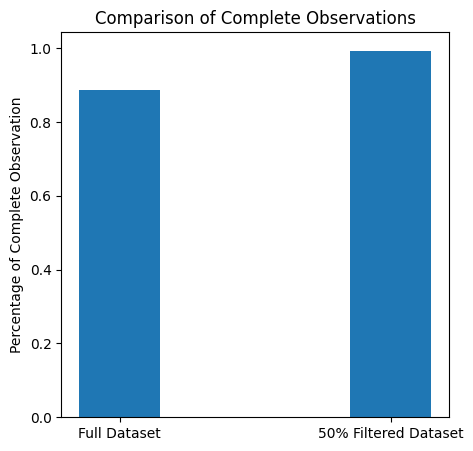

Full dataset complete observation percentage: 88.67%
50% filtered dataset complete observation percentage: 99.37%


In [21]:
fig = plt.figure(figsize=(5, 5))
plt.bar(['Full Dataset', '50% Filtered Dataset'], 
        [clean_full_dataset['hospital_observed_48h'].sum() / clean_full_dataset.shape[0], 
         clean_filtered_dataset['hospital_observed_48h'].sum() / clean_filtered_dataset.shape[0]], width=0.3)
plt.ylabel('Percentage of Complete Observation')
plt.title('Comparison of Complete Observations')
plt.show()
print(f"Full dataset complete observation percentage: {clean_full_dataset['hospital_observed_48h'].sum() / clean_full_dataset.shape[0] * 100:.2f}%")
print(f"50% filtered dataset complete observation percentage: {clean_filtered_dataset['hospital_observed_48h'].sum() / clean_filtered_dataset.shape[0] * 100:.2f}%")